# Health Insurance → Vehicle Insurance Cross-Sell Prediction

**Problem type:** Binary classification on an imbalanced target (≈12 % positives)  
**Data:** 381,109 health-insurance customers · 10 predictors · target `Response` (1 = interested in vehicle insurance)  
**Deliverables:** this notebook + `app.py` (Streamlit scoring app) that loads the model saved in section 11.

### Business question
The insurer wants to cross-sell vehicle insurance to its health customers. Calling everyone is expensive, so the model must **rank customers by purchase likelihood** so that sales teams contact the best prospects first.

### What this version does properly
| Issue common in cross-sell notebooks | How it is handled here |
|---|---|
| Over-sampling *before* the train/test split (duplicates leak into the test set and inflate scores) | Split first. Imbalance is handled with ranking metrics + a business-driven threshold. Section 6 *demonstrates* the leak and its size. |
| Accuracy as the headline metric | ROC-AUC, **PR-AUC**, recall/lift in the top 30 %, and expected profit |
| AUC computed from hard 0/1 predictions | Always computed from `predict_proba` |
| Important features dropped (`Region_Code`, `Policy_Sales_Channel`) | Used, with leakage-safe encoding inside the pipeline |
| Model picked by looking at the test set | Model picked on **cross-validated** train performance; test set is scored once |
| No decision rule | Threshold chosen on out-of-fold predictions from explicit cost/benefit assumptions |

**Run it:** put the CSV at `data/train.csv` (or let the notebook download it), then *Run all*. Runtime is roughly 10–20 minutes on a laptop CPU.

## 1. Setup

In [ ]:
import warnings, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score, f1_score, accuracy_score,
                             brier_score_loss)
from scipy.stats import randint, uniform, loguniform
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler

warnings.filterwarnings("ignore", message=".*feature names.*")   # cosmetic sklearn/lightgbm message only
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
PALETTE = {"pos": "#2a7de1", "neg": "#b8c4d6", "accent": "#e4572e"}
Path("models").mkdir(exist_ok=True)

## 2. Know your data

In [ ]:
LOCAL = Path("data/train.csv")
URL = ("https://raw.githubusercontent.com/Shaikh-Mazher01/Classification_Health_Insurance/main/"
       "TRAIN-HEALTH%20INSURANCE%20CROSS%20SELL%20PREDICTION.csv")
df = pd.read_csv(LOCAL if LOCAL.exists() else URL)       # no Google-Drive dependency
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 381,109 | Columns: 12


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


| Column | Meaning |
|---|---|
| `id` | Customer identifier (dropped – carries no information) |
| `Gender`, `Age` | Demographics |
| `Driving_License` | 1 = holds a driving licence |
| `Region_Code` | Anonymised region (53 values) |
| `Previously_Insured` | 1 = customer **already has vehicle insurance** |
| `Vehicle_Age` | `< 1 Year`, `1-2 Year`, `> 2 Years` |
| `Vehicle_Damage` | Vehicle damaged in the past (Yes / No) |
| `Annual_Premium` | Health-insurance premium paid per year |
| `Policy_Sales_Channel` | Anonymised outreach channel (155 values: agents, phone, mail …) |
| `Vintage` | Days the customer has been with the company |
| `Response` | **Target** – 1 = interested in vehicle insurance |

## 3. Data quality checks

In [ ]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})
display(quality)
print("Rows identical to another row apart from id:", df.drop(columns="id").duplicated().sum())
print("Duplicate ids:", df["id"].duplicated().sum())
display(df[["Age", "Annual_Premium", "Vintage"]].describe().round(1))
at_floor = (df["Annual_Premium"] == df["Annual_Premium"].min()).mean()
print(f"Share of customers sitting exactly at the minimum premium ({df['Annual_Premium'].min():,.0f}): {at_floor:.1%}")
print(f"Premium skewness: {df['Annual_Premium'].skew():.2f} | 99th percentile: {df['Annual_Premium'].quantile(.99):,.0f} | max: {df['Annual_Premium'].max():,.0f}")

,dtype,missing,unique
id,int64,0,381109
Gender,str,0,2
Age,int64,0,66
Driving_License,int64,0,2
Region_Code,float64,0,53
Previously_Insured,int64,0,2
Vehicle_Age,str,0,3
Vehicle_Damage,str,0,2
Annual_Premium,float64,0,48838
Policy_Sales_Channel,float64,0,155


Rows identical to another row apart from id: 269
Duplicate ids: 0


,Age,Annual_Premium,Vintage
count,381109.0,381109.0,381109.0
mean,38.8,30564.4,154.3
std,15.5,17213.2,83.7
min,20.0,2630.0,10.0
25%,25.0,24405.0,82.0
50%,36.0,31669.0,154.0
75%,49.0,39400.0,227.0
max,85.0,540165.0,299.0


Share of customers sitting exactly at the minimum premium (2,630): 17.0%
Premium skewness: 1.77 | 99th percentile: 72,963 | max: 540,165


**Findings**
- No missing values and no duplicate ids. 269 rows share *identical feature values and response* with another row but have different ids; they are plausibly different customers with the same profile (0.07 % of the data), so they are **kept**.
- `Annual_Premium` is strongly right-skewed (a few very large premiums) and **17 % of customers sit exactly on the minimum value (2,630)**, which looks like a pricing floor. Tree models handle this naturally; the linear model gets a `log1p` transform inside its pipeline.
- `Driving_License` is 1 for 99.8 % of customers, so it carries almost no information.
- Outliers are **kept**: very large premiums are legitimate policies, not errors, and the models used are robust to them.

## 4. Exploratory analysis (univariate → bivariate → multivariate)
Every chart answers: *why this chart, what it shows, and what it means for the business.* A response **rate** (share of customers who said yes) is used instead of raw counts wherever groups differ in size, because counts alone hide conversion.

In [ ]:
AGE_BINS = [19, 25, 35, 45, 55, 65, 100]
AGE_LABELS = ["20-25", "26-35", "36-45", "46-55", "56-65", "66+"]
eda = df.copy()
eda["Age_band"] = pd.cut(eda["Age"], AGE_BINS, labels=AGE_LABELS)
BASE_RATE = eda["Response"].mean()

def rate_bar(ax, key, title, order=None, rot=0, min_n=0, color=None):
    """Bar chart of response rate per group; each bar labelled with rate and group size."""
    g = eda.groupby(key, observed=True)["Response"].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    if order is not None:
        g = g.loc[order]
    ax.bar(g.index.astype(str), g["mean"], color=color or PALETTE["pos"])
    ax.axhline(BASE_RATE, color=PALETTE["accent"], ls="--", lw=1.2, label=f"overall {BASE_RATE:.1%}")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m, f"{m:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title); ax.set_ylabel("Response rate"); ax.set_ylim(0, g["mean"].max() * 1.3 + 0.005)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.tick_params(axis="x", rotation=rot)
    ax.legend(loc="upper left", fontsize=8)
    return g

#### Chart 1 – Target balance (univariate)

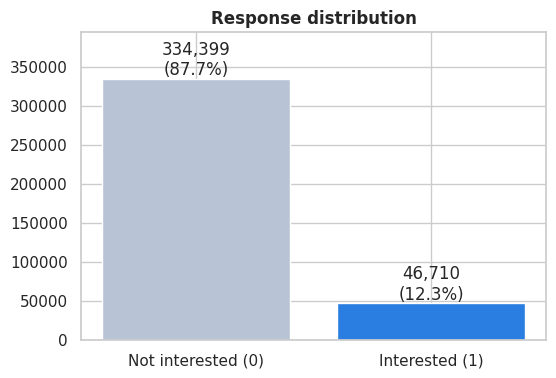

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = eda["Response"].value_counts().sort_index()
ax.bar(["Not interested (0)", "Interested (1)"], counts.values, color=[PALETTE["neg"], PALETTE["pos"]])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(eda):.1%})", ha="center", va="bottom")
ax.set_title("Response distribution"); ax.set_ylim(0, counts.max() * 1.18); plt.show()

**Why this chart:** a bar chart of the target shows class balance at a glance, which decides the metric and modelling strategy.  
**Insight:** only **12.3 %** of customers are interested (46,710 of 381,109) – a ~7:1 imbalance.  
**Business impact:** a model that says "nobody is interested" is 87.7 % accurate, so **accuracy is meaningless here**. We use ROC-AUC, PR-AUC, lift and profit instead. *Risk:* contacting customers at random wastes ~88 % of the effort.

#### Chart 2 – Age distribution (univariate)

/tmp/ipykernel_172/2827068325.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=eda, x="Response", y="Age", palette=[PALETTE["neg"], PALETTE["pos"]], ax=ax[1])


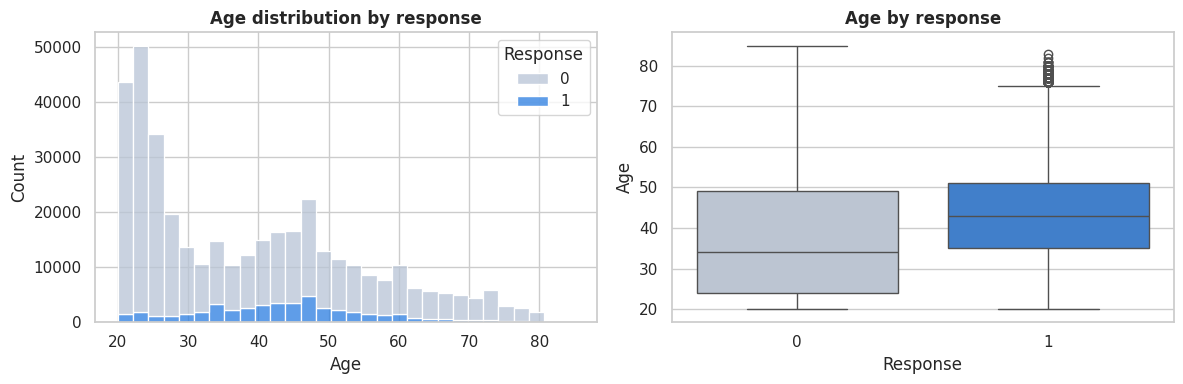

             count  mean   std   min   25%   50%   75%   max
Response                                                    
0         334399.0  38.2  15.8  20.0  24.0  34.0  49.0  85.0
1          46710.0  43.4  12.2  20.0  35.0  43.0  51.0  83.0


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=eda, x="Age", hue="Response", bins=30, multiple="stack",
             palette=[PALETTE["neg"], PALETTE["pos"]], ax=ax[0]); ax[0].set_title("Age distribution by response")
sns.boxplot(data=eda, x="Response", y="Age", palette=[PALETTE["neg"], PALETTE["pos"]], ax=ax[1])
ax[1].set_title("Age by response"); plt.tight_layout(); plt.show()
print(eda.groupby("Response")["Age"].describe().round(1))

**Why this chart:** a histogram shows the shape of the customer base; the box plot compares the typical age of responders vs non-responders.  
**Insight:** the base is young and right-skewed (median 36, a quarter of customers are ≤ 25). Responders are clearly **older** than non-responders.  
**Business impact:** the customer base is dominated by an age group that rarely buys (see Chart 3), so blanket campaigns dilute conversion. No age outliers need treatment (range 20–85 is plausible).

#### Chart 3 – Response rate by age band (bivariate: numeric → categorical)

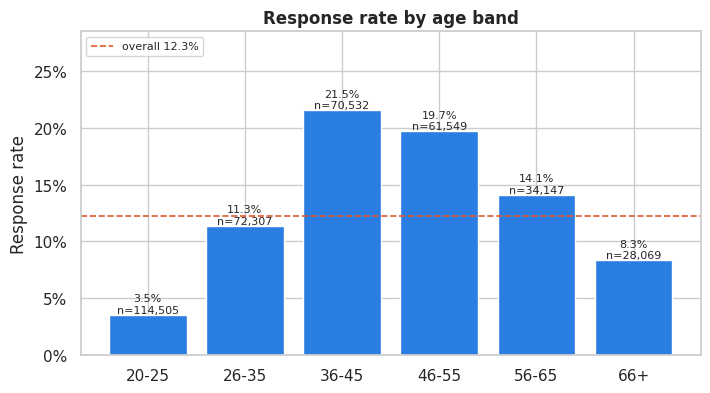

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.2))
_ = rate_bar(ax, "Age_band", "Response rate by age band"); plt.show()

**Why this chart:** binning a continuous variable and plotting the *rate* reveals non-linear relationships that a correlation coefficient would miss.  
**Insight:** a clear **inverted-U**: 3.5 % for ages 20–25, rising to **21.5 % at 36–45** and 19.7 % at 46–55, then falling to 8.3 % for 66+.  
**Business impact:** prioritise 35–55-year-olds. *Negative:* the under-25 segment is large but converts at 3.5 % – heavy spend there is the least efficient. The relationship is non-linear, so tree models will beat plain logistic regression.

#### Chart 4 – Gender

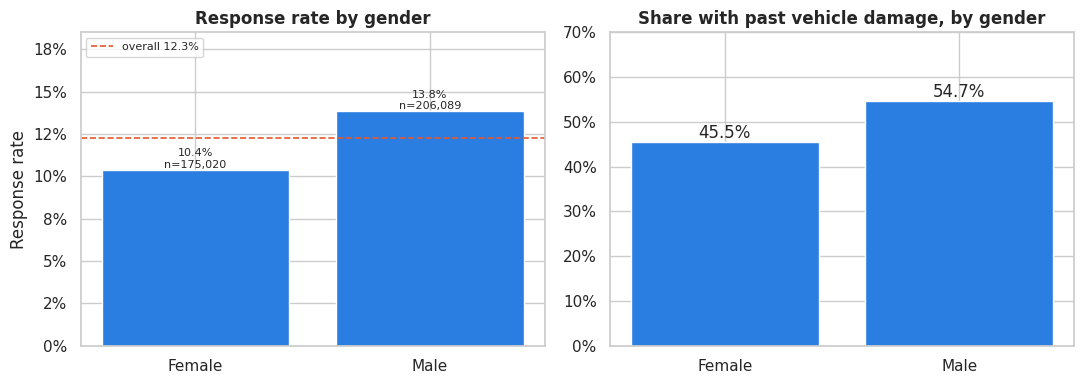

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
rate_bar(ax[0], "Gender", "Response rate by gender")
dmg = eda.groupby("Gender")["Vehicle_Damage"].apply(lambda s: (s == "Yes").mean())
ax[1].bar(dmg.index, dmg.values, color=PALETTE["pos"])
for i, v in enumerate(dmg.values): ax[1].text(i, v, f"{v:.1%}", ha="center", va="bottom")
ax[1].set_title("Share with past vehicle damage, by gender"); ax[1].set_ylim(0, 0.7)
ax[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); plt.tight_layout(); plt.show()

**Why this chart:** gender is the first demographic split people ask about; the second panel checks whether it is a proxy for something else.  
**Insight:** men respond more (**13.8 % vs 10.4 %**), but men also report vehicle damage more often (54.7 % vs 45.5 %), and damage is a far stronger driver (Chart 6). Part of the "gender effect" is therefore damage history.  
**Business impact:** do **not** target by gender – the gap is modest and largely explained by other variables. Using gender directly could also raise fairness concerns; the model should rely on behavioural features first.

#### Chart 5 – Previously insured (the strongest signal)

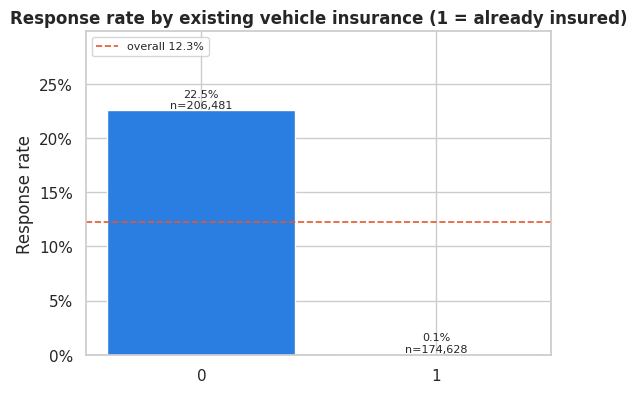

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.2))
rate_bar(ax, "Previously_Insured", "Response rate by existing vehicle insurance (1 = already insured)"); plt.show()

**Why this chart:** `Previously_Insured` is the most intuitive business variable – someone who already has vehicle cover has little reason to buy again.  
**Insight:** **22.5 % vs 0.1 %.** Customers who already hold vehicle insurance almost never respond (only 158 of 174,628).  
**Business impact:** **exclude previously-insured customers from cold campaigns** – 46 % of the base (174,628 people) is essentially zero-yield. This single rule removes almost half the contact list at negligible loss of sales.

#### Chart 6 – Vehicle damage

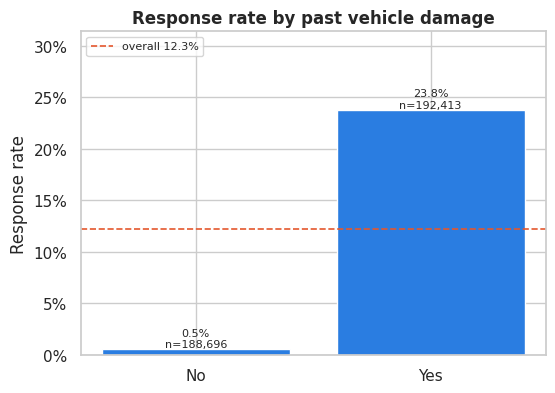

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.2))
rate_bar(ax, "Vehicle_Damage", "Response rate by past vehicle damage"); plt.show()

**Why this chart:** damage history proxies perceived risk, which drives the need for insurance.  
**Insight:** **23.8 % (damage) vs 0.5 % (no damage)** – a ~50× gap, the largest single-variable separation in the data.  
**Business impact:** customers who have experienced damage are receptive; those who have not are almost never. Messaging for this segment can emphasise repair-cost protection. *Caveat:* damage and prior insurance are correlated (Chart 13), so their effects overlap.

#### Chart 7 – Vehicle age

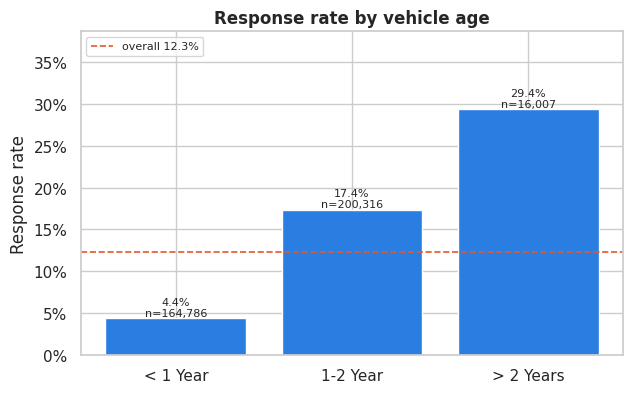

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.2))
rate_bar(ax, "Vehicle_Age", "Response rate by vehicle age", order=["< 1 Year", "1-2 Year", "> 2 Years"]); plt.show()

**Why this chart:** vehicle age is an ordered category, so an ordered bar chart shows a trend.  
**Insight:** response rises with vehicle age: **4.4 % → 17.4 % → 29.4 %**. Vehicles older than 2 years are only 4.2 % of customers but convert best.  
**Business impact:** older vehicles = higher perceived risk and fewer new-car bundled policies. This is a small, high-yield pocket worth a dedicated offer. *Caveat:* part of the "< 1 year" weakness is because those owners are mostly already insured (Chart 16).

#### Chart 8 – Driving licence

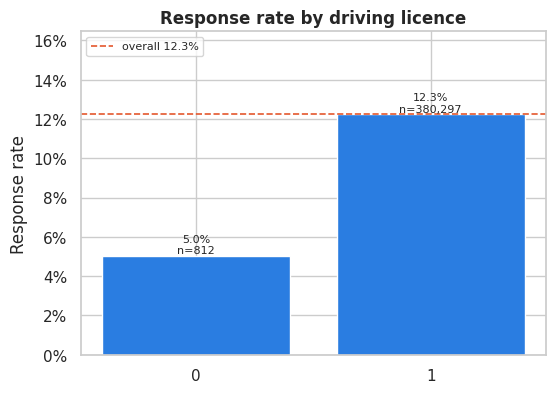

Driving_License
1    0.9979
0    0.0021
Name: proportion, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.2))
rate_bar(ax, "Driving_License", "Response rate by driving licence"); plt.show()
print(eda["Driving_License"].value_counts(normalize=True).round(4))

**Why this chart:** a licence is a precondition for owning a vehicle, so it is an obvious candidate feature.  
**Insight:** 99.8 % of customers hold a licence. The 812 without one convert at 5.0 % versus 12.3 %, but the group is too small to be reliable.  
**Business impact:** negligible – there is almost no variation to exploit. The feature is kept (it costs nothing) but is expected to rank last in importance.

#### Chart 9 – Annual premium (distribution and relationship)

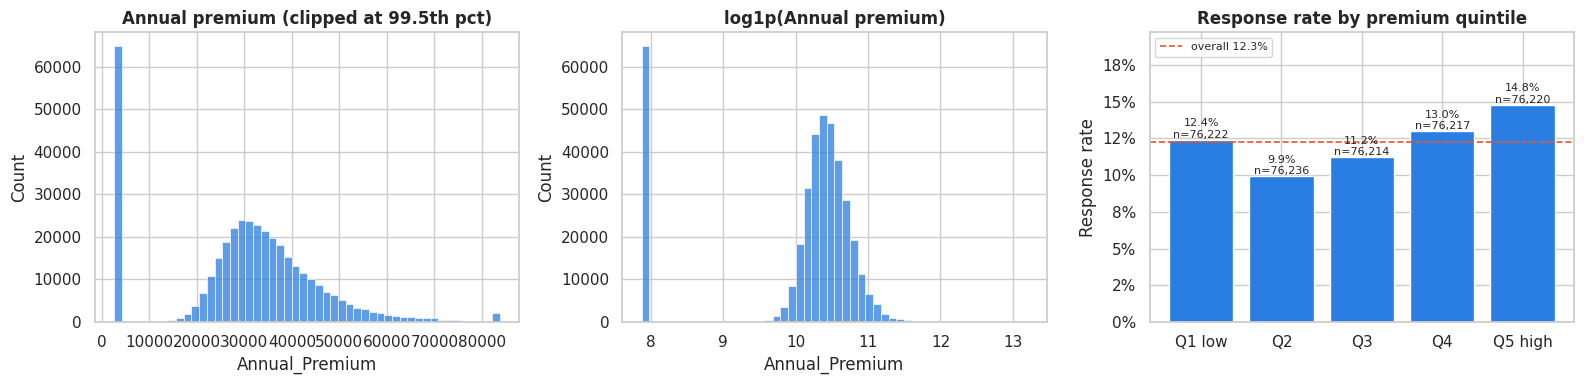

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(eda["Annual_Premium"].clip(upper=eda["Annual_Premium"].quantile(.995)), bins=50, ax=ax[0], color=PALETTE["pos"])
ax[0].set_title("Annual premium (clipped at 99.5th pct)")
sns.histplot(np.log1p(eda["Annual_Premium"]), bins=50, ax=ax[1], color=PALETTE["pos"]); ax[1].set_title("log1p(Annual premium)")
eda["Premium_quintile"] = pd.qcut(eda["Annual_Premium"], 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"], duplicates="drop")
rate_bar(ax[2], "Premium_quintile", "Response rate by premium quintile"); plt.tight_layout(); plt.show()

**Why this chart:** three panels – raw shape, the effect of the log transform, and the link to the target.  
**Insight:** the raw premium has a long right tail and a spike at the 2,630 floor; `log1p` makes it far more symmetric. The response rate varies only mildly (9.9 %–14.8 %) across quintiles, with the **top quintile highest**.  
**Business impact:** premium is a *weak* standalone predictor. High-premium customers are slightly more receptive and more valuable, so they are a reasonable tie-breaker for ranking. Log-scaling matters for the linear model only.

#### Chart 10 – Vintage (tenure)

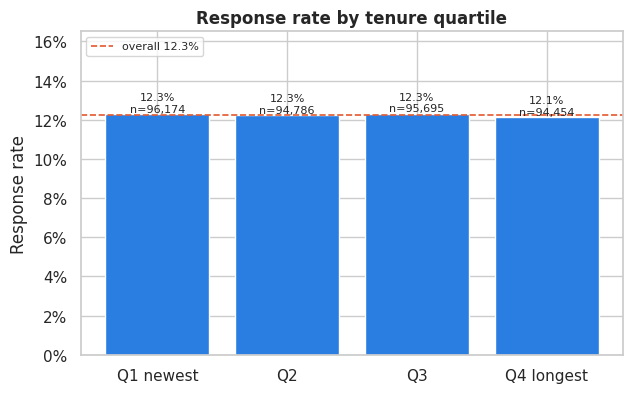

In [ ]:
eda["Vintage_quartile"] = pd.qcut(eda["Vintage"], 4, labels=["Q1 newest", "Q2", "Q3", "Q4 longest"])
fig, ax = plt.subplots(figsize=(7, 4.2)); rate_bar(ax, "Vintage_quartile", "Response rate by tenure quartile"); plt.show()

**Why this chart:** tenure is often assumed to drive loyalty and cross-sell.  
**Insight:** the rate is **flat at ≈ 12.3 %** in every quartile; `Vintage` is roughly uniform and unrelated to the response.  
**Business impact:** *do not* base campaigns on how long someone has been a customer. Expect `Vintage` to show ~zero importance in the model – a useful sanity check that the model is not inventing signal.

#### Chart 11 – Region code

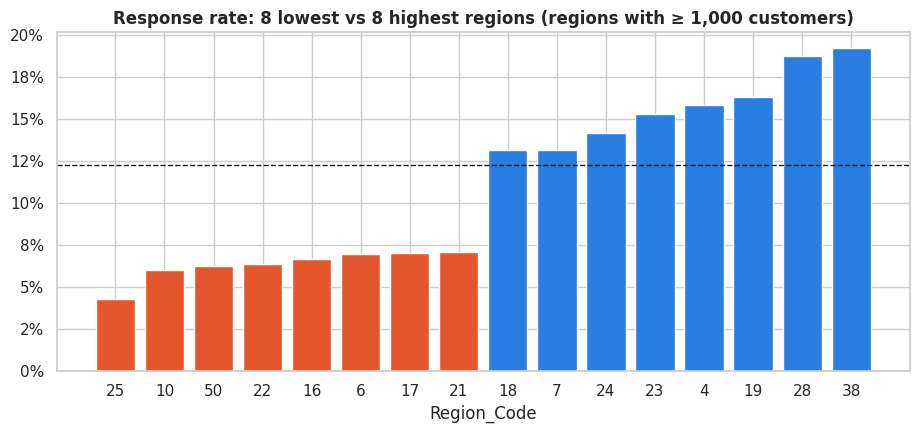

53 regions; region 28 holds 27.9% of customers at 18.7% response.


In [ ]:
reg = eda.groupby("Region_Code")["Response"].agg(["mean", "size"]).query("size >= 1000").sort_values("mean")
sel = pd.concat([reg.head(8), reg.tail(8)])
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(sel.index.astype(int).astype(str), sel["mean"], color=[PALETTE["accent"]] * 8 + [PALETTE["pos"]] * 8)
ax.axhline(BASE_RATE, color="k", ls="--", lw=1); ax.set_title("Response rate: 8 lowest vs 8 highest regions (regions with ≥ 1,000 customers)")
ax.set_xlabel("Region_Code"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); plt.show()
print(f"{eda['Region_Code'].nunique()} regions; region 28 holds {(eda['Region_Code']==28).mean():.1%} of customers at {eda.loc[eda['Region_Code']==28,'Response'].mean():.1%} response.")

**Why this chart:** with 53 regions a full bar chart is unreadable, so the extremes are compared against the average.  
**Insight:** rates range from **~4 % (region 25) to ~19 % (regions 28, 38)**. Region 28 alone holds **27.9 %** of customers and converts at 18.7 %.  
**Business impact:** geography is a real lever – shift outreach toward high-converting regions and investigate why low regions (e.g. 25, 10) underperform (competitors, product fit, agent quality). *Risk:* heavy dependence on one region.

#### Chart 12 – Policy sales channel

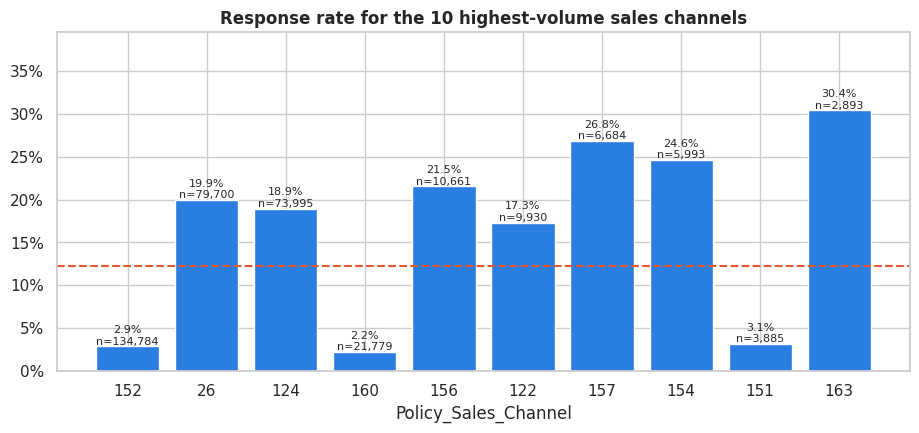

155 channels; channel 152 handles 35.4% of customers.


In [ ]:
ch = eda.groupby("Policy_Sales_Channel")["Response"].agg(["mean", "size"]).sort_values("size", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(ch.index.astype(int).astype(str), ch["mean"], color=PALETTE["pos"])
for i, (m, n) in enumerate(zip(ch["mean"], ch["size"])): ax.text(i, m, f"{m:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
ax.axhline(BASE_RATE, color=PALETTE["accent"], ls="--"); ax.set_ylim(0, ch["mean"].max() * 1.3)
ax.set_title("Response rate for the 10 highest-volume sales channels"); ax.set_xlabel("Policy_Sales_Channel")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); plt.show()
print(f"{eda['Policy_Sales_Channel'].nunique()} channels; channel 152 handles {(eda['Policy_Sales_Channel']==152).mean():.1%} of customers.")

**Why this chart:** channels differ in cost and quality; showing the high-volume ones next to their conversion makes the trade-off visible.  
**Insight:** a huge divergence. **Channel 152 reaches 35 % of customers but converts at only 2.9 %**, and channel 160 at 2.2 %, while channels 26 and 124 convert at ~19–20 %.  
**Business impact:** the largest channel is the least productive – re-allocating contact effort from 152/160 to 26/124/156/157 could multiply conversions without more spend. This is among the highest-value findings and a reason not to drop this feature.

#### Chart 13 – Previously insured × vehicle damage (multivariate)

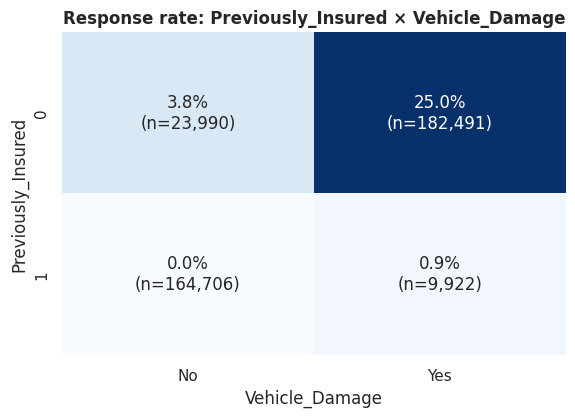

In [ ]:
pt = eda.pivot_table(index="Previously_Insured", columns="Vehicle_Damage", values="Response", aggfunc="mean")
nn = eda.pivot_table(index="Previously_Insured", columns="Vehicle_Damage", values="Response", aggfunc="size")
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.heatmap(pt, annot=pt.map(lambda v: f"{v:.1%}") + "\n(n=" + nn.map(lambda v: f"{v:,}") + ")", fmt="", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Response rate: Previously_Insured × Vehicle_Damage"); plt.show()

**Why this chart:** a heat-map shows how two strong binary features interact.  
**Insight:** the pocket **not insured + vehicle damaged is 47.9 % of all customers (182,491) and converts at 25.0 %**. Every other combination is ≤ 3.8 %; the insured-and-undamaged group is **0.0 %**.  
**Business impact:** a simple two-question rule already isolates the profitable half of the base. The model must therefore *rank within* that pocket (age, region, channel, vehicle age) – that is where machine learning adds value beyond the rule.

#### Chart 14 – Age band × vehicle age (multivariate)

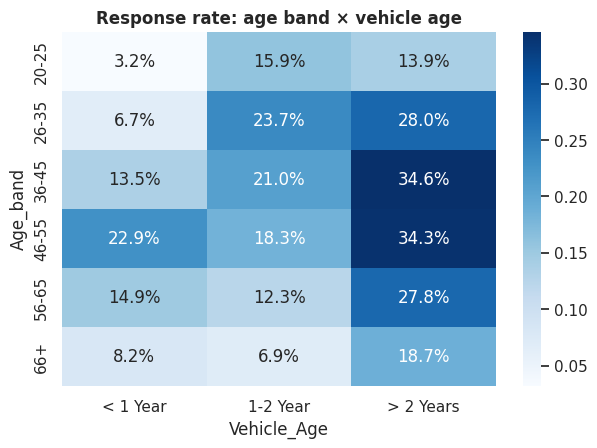

In [ ]:
pv = eda.pivot_table(index="Age_band", columns="Vehicle_Age", values="Response", aggfunc="mean", observed=True)[["< 1 Year", "1-2 Year", "> 2 Years"]]
fig, ax = plt.subplots(figsize=(7, 4.6))
sns.heatmap(pv, annot=True, fmt=".1%", cmap="Blues", ax=ax); ax.set_title("Response rate: age band × vehicle age"); plt.show()

**Why this chart:** checks whether the age effect and the vehicle-age effect reinforce each other.  
**Insight:** the best cells are **36–55-year-olds with vehicles over 2 years (≈ 34–35 %)**; the worst is **under-25s with new vehicles (3.2 %)**. Vehicle age matters most in the middle ages.  
**Business impact:** gives sales teams concrete, easily-explained target personas. It also shows the features interact, which is why boosted trees outperform a linear model here.

#### Chart 15 – Correlation heat-map (multivariate)

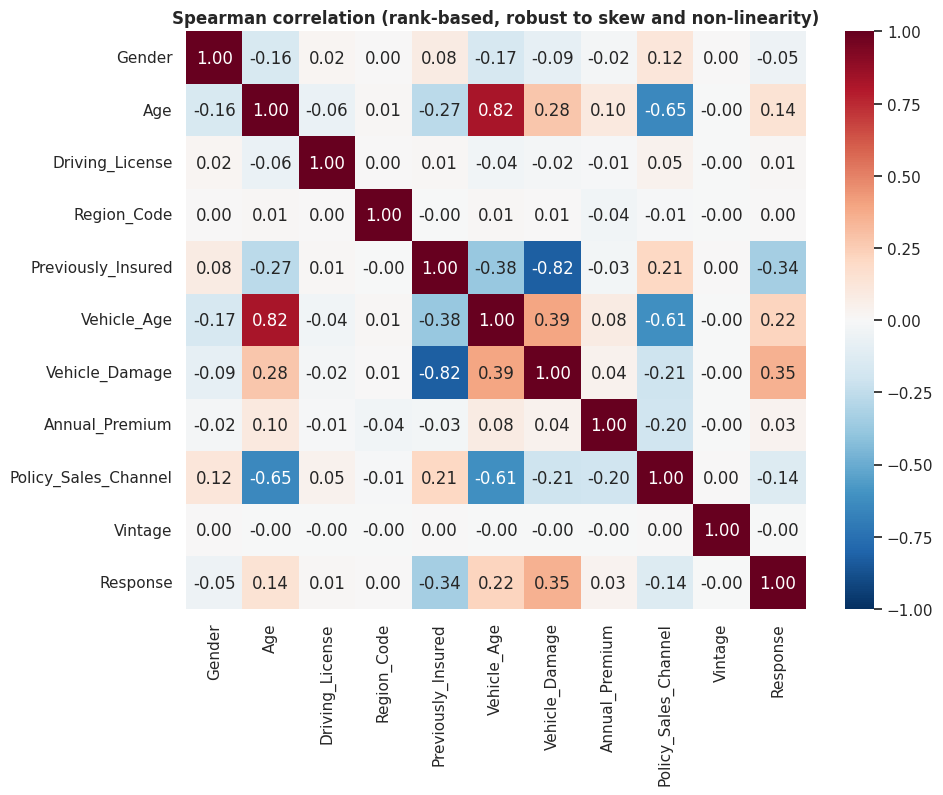

Vehicle_Damage          0.35
Previously_Insured     -0.34
Vehicle_Age             0.22
Age                     0.14
Policy_Sales_Channel   -0.14
Gender                 -0.05
Annual_Premium          0.03
Driving_License         0.01
Region_Code             0.00
Vintage                -0.00


In [ ]:
enc = eda.assign(Gender=eda["Gender"].map({"Male": 0, "Female": 1}),
                 Vehicle_Damage=eda["Vehicle_Damage"].map({"No": 0, "Yes": 1}),
                 Vehicle_Age=eda["Vehicle_Age"].map({"< 1 Year": 0, "1-2 Year": 1, "> 2 Years": 2}))
cols = ["Gender", "Age", "Driving_License", "Region_Code", "Previously_Insured", "Vehicle_Age", "Vehicle_Damage",
        "Annual_Premium", "Policy_Sales_Channel", "Vintage", "Response"]
corr = enc[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (rank-based, robust to skew and non-linearity)"); plt.show()
print(corr["Response"].drop("Response").sort_values(key=abs, ascending=False).round(2).to_string())

**Why this chart:** Spearman (rank) correlation is used because several variables are skewed or categorical.  
**Insight:** the strongest links with `Response` are `Vehicle_Damage` (+), `Previously_Insured` (−) and `Vehicle_Age` (+). `Previously_Insured` is very strongly (negatively) correlated with `Vehicle_Damage` (≈ −0.82) and moderately with `Vehicle_Age` (≈ −0.38) – these predictors overlap heavily. `Age` is also strongly tied to `Vehicle_Age` (≈ 0.82) and to `Policy_Sales_Channel` (≈ −0.65), i.e. channels are effectively aimed at different age groups. `Vintage`, `Region_Code` and `Driving_License` show ≈ 0 linear correlation (region and channel are *identifiers*, so their value is non-linear and invisible here).  
**Business impact:** low correlation does **not** mean low value for codes like region/channel (Charts 11–12). Correlated features are fine for tree models, but would require care (regularisation) in a linear model.

#### Chart 16 – Why young customers look unattractive: they are already insured

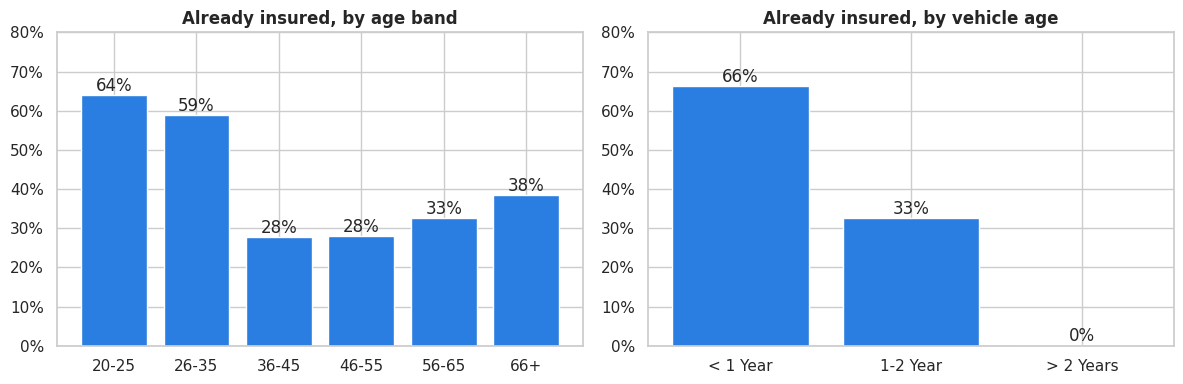

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pi_age = eda.groupby("Age_band", observed=True)["Previously_Insured"].mean()
ax[0].bar(pi_age.index.astype(str), pi_age.values, color=PALETTE["pos"]); ax[0].set_title("Already insured, by age band")
pi_veh = eda.groupby("Vehicle_Age")["Previously_Insured"].mean().loc[["< 1 Year", "1-2 Year", "> 2 Years"]]
ax[1].bar(pi_veh.index, pi_veh.values, color=PALETTE["pos"]); ax[1].set_title("Already insured, by vehicle age")
for a, s in zip(ax, [pi_age, pi_veh]):
    for i, v in enumerate(s.values): a.text(i, v, f"{v:.0%}", ha="center", va="bottom")
    a.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); a.set_ylim(0, 0.8)
plt.tight_layout(); plt.show()

**Why this chart:** explains *why* the age and vehicle-age patterns in Charts 3 and 7 exist, instead of just describing them.  
**Insight:** **64 % of 20–25-year-olds and 66 % of owners of new (< 1 year) vehicles are already insured**, versus only ~28 % of 36–55-year-olds and 0.3 % of owners of vehicles over 2 years.  
**Business impact:** young and new-vehicle customers are not "uninterested" – they are mostly *already served* (likely bundled at purchase). The opportunity is **at renewal time**, so timing a campaign to the vehicle's first-policy anniversary may unlock this segment.

## 5. Leakage-safe feature pipeline and train/test split
All transformations live **inside** scikit-learn pipelines, so every statistic (scaling means, one-hot categories) is learned from training folds only, and the saved model accepts raw customer fields (this is what `app.py` relies on).

**Split first, stratified.** 80 % train / 20 % test. The test set keeps the real 12 % class ratio and is touched **once**, at the end.

In [ ]:
FEATURES = ["Gender", "Age", "Driving_License", "Region_Code", "Previously_Insured", "Vehicle_Age",
            "Vehicle_Damage", "Annual_Premium", "Policy_Sales_Channel", "Vintage"]
CAT_ORDER = [["Male", "Female"], ["< 1 Year", "1-2 Year", "> 2 Years"], ["No", "Yes"]]
ORD_COLS = ["Gender", "Vehicle_Age", "Vehicle_Damage"]

X = df[FEATURES].copy()
y = df["Response"].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"train: {X_train.shape} (positive rate {y_train.mean():.2%}) | test: {X_test.shape} (positive rate {y_test.mean():.2%})")

def make_ordinal():
    return OrdinalEncoder(categories=CAT_ORDER, handle_unknown="use_encoded_value", unknown_value=-1)

# Tree models: ordinal-encode the 3 text columns, pass numerics through. Region/channel kept as numeric codes.
pre_tree = ColumnTransformer(
    [("ord", make_ordinal(), ORD_COLS),
     ("num", "passthrough", ["Age", "Driving_License", "Region_Code", "Previously_Insured",
                             "Annual_Premium", "Policy_Sales_Channel", "Vintage"])])

# Linear model: log+scale premium, scale age/tenure, one-hot the high-cardinality codes (rare levels pooled).
pre_lr = ColumnTransformer(
    [("ord", make_ordinal(), ORD_COLS),
     ("prem", Pipeline([("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), ["Annual_Premium"]),
     ("num", StandardScaler(), ["Age", "Vintage"]),
     ("bin", "passthrough", ["Driving_License", "Previously_Insured"]),
     ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=200), ["Region_Code", "Policy_Sales_Channel"])])

train: (304887, 10) (positive rate 12.26%) | test: (76222, 10) (positive rate 12.26%)


## 6. Demonstration: why over-sampling *before* splitting gives misleading scores
Random over-sampling copies minority rows. If this happens **before** `train_test_split`, identical customers land in both train and test, so flexible models (Random Forest, KNN, Decision Tree) are rewarded for memorising. The experiment below uses a 60k sample and the *same* model both times; the only difference is the order of operations.

In [ ]:
sub = df.sample(60_000, random_state=SEED)
Xs = pre_tree.fit_transform(sub[FEATURES])     # stateless mapping only, safe to apply before splitting
ys = sub["Response"].to_numpy()
ros = RandomOverSampler(random_state=SEED)

def rf(): return RandomForestClassifier(n_estimators=60, random_state=SEED, n_jobs=-1)
def leak_share(train_X, test_X):
    seen = set(map(tuple, np.round(train_X, 4)))
    return float(np.mean([tuple(r) in seen for r in np.round(test_X, 4)]))

# WRONG: over-sample the whole dataset, then split
Xw, yw = ros.fit_resample(Xs, ys)
Xa, Xb, ya, yb = train_test_split(Xw, yw, test_size=0.3, random_state=SEED)
p_wrong = rf().fit(Xa, ya).predict_proba(Xb)[:, 1]
wrong = dict(setup="Over-sample → split (WRONG)", test_rows=len(yb), roc_auc=roc_auc_score(yb, p_wrong),
             recall_at_0_5=recall_score(yb, p_wrong >= .5), precision_at_0_5=precision_score(yb, p_wrong >= .5),
             test_rows_also_in_train=leak_share(Xa, Xb))

# RIGHT: split (stratified), over-sample only the training part, test on the untouched distribution
Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=SEED)
Xa_r, ya_r = ros.fit_resample(Xa, ya)
p_right = rf().fit(Xa_r, ya_r).predict_proba(Xb)[:, 1]
right = dict(setup="Split → over-sample train only (RIGHT)", test_rows=len(yb), roc_auc=roc_auc_score(yb, p_right),
             recall_at_0_5=recall_score(yb, p_right >= .5), precision_at_0_5=precision_score(yb, p_right >= .5),
             test_rows_also_in_train=leak_share(Xa_r, Xb))
leak_df = pd.DataFrame([wrong, right]).set_index("setup")
display(leak_df.round(3))

,test_rows,roc_auc,recall_at_0_5,precision_at_0_5,test_rows_also_in_train
setup,,,,,
Over-sample → split (WRONG),31482,0.998,0.995,0.885,0.495
Split → over-sample train only (RIGHT),18000,0.834,0.301,0.359,0.000


**Reading the table.** In the wrong setup the test set is artificially balanced and a large share of test rows have an exact twin in the training data, so recall looks near-perfect for a model that has largely memorised. In the right setup the model is judged on the real 12 % distribution and the scores drop to honest values. **The numbers in sections 7–10 use the correct setup.** The inflated 0.93–0.99 recall/AUC figures reported for Random Forest, Decision Tree and KNN in the first version of this project were artefacts of this leak.

## 7. Model comparison (stratified 3-fold CV on the training set, then a single test evaluation)
**Metrics and what they mean for the business**
- **ROC-AUC** – probability that a random buyer is scored above a random non-buyer. 0.5 = coin flip. Threshold-independent.
- **PR-AUC (average precision)** – summarises precision vs recall; the right headline metric when positives are rare. The *no-skill* value equals the base rate (**≈ 0.12**), not 0.5.
- **Recall in top 30 %** – share of all buyers found if the sales team contacts only the 30 % highest-scored customers.
- **Lift in top 30 %** – how many times better than random contact (e.g. 2.5× means 2.5× the base conversion rate).

Imbalance is handled by **ranking + threshold choice** (section 9) rather than by resampling, so probabilities stay realistic and nothing is duplicated.

In [ ]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
TOP_FRAC = 0.30

def top_frac_metrics(y_true, proba, frac=TOP_FRAC):
    y_arr = np.asarray(y_true); k = int(len(y_arr) * frac)
    top = y_arr[np.argsort(-proba)[:k]]
    return top.sum() / y_arr.sum(), top.mean() / y_arr.mean()

fitted, test_proba, rows = {}, {}, []

def run(name, pipe):
    t0 = time.time()
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring={"roc": "roc_auc", "pr": "average_precision"}, n_jobs=1)
    model = clone(pipe).fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    rec, lift = top_frac_metrics(y_test, p)
    fitted[name], test_proba[name] = model, p
    rows.append(dict(model=name, cv_roc_auc=cv["test_roc"].mean(), cv_pr_auc=cv["test_pr"].mean(),
                     test_roc_auc=roc_auc_score(y_test, p), test_pr_auc=average_precision_score(y_test, p),
                     test_recall_top30=rec, test_lift_top30=lift, brier=brier_score_loss(y_test, p)))
    print(f"{name:<28} done in {time.time()-t0:5.0f}s | CV PR-AUC {cv['test_pr'].mean():.4f} | test PR-AUC {rows[-1]['test_pr_auc']:.4f}")

baselines = {
    "Dummy (prior)":       Pipeline([("pre", pre_tree), ("clf", DummyClassifier(strategy="prior"))]),
    "Logistic Regression": Pipeline([("pre", pre_lr), ("clf", LogisticRegression(max_iter=500))]),
    "Decision Tree":       Pipeline([("pre", pre_tree), ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEED))]),
    "Random Forest":       Pipeline([("pre", pre_tree), ("clf", RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=50,
                                                                                       max_samples=0.4, n_jobs=-1, random_state=SEED))]),
    "LightGBM":            Pipeline([("pre", pre_tree), ("clf", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=63,
                                                                               n_jobs=-1, random_state=SEED, verbose=-1))]),
    "XGBoost":             Pipeline([("pre", pre_tree), ("clf", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, subsample=0.8,
                                                                              colsample_bytree=0.8, tree_method="hist", eval_metric="logloss",
                                                                              n_jobs=-1, random_state=SEED))]),
}
for n, p in baselines.items():
    run(n, p)

Dummy (prior)                done in     2s | CV PR-AUC 0.1226 | test PR-AUC 0.1226


Logistic Regression          done in     8s | CV PR-AUC 0.3363 | test PR-AUC 0.3383


Decision Tree                done in     3s | CV PR-AUC 0.3374 | test PR-AUC 0.3377


Random Forest                done in    58s | CV PR-AUC 0.3657 | test PR-AUC 0.3641


LightGBM                     done in    23s | CV PR-AUC 0.3661 | test PR-AUC 0.3665


XGBoost                      done in    22s | CV PR-AUC 0.3640 | test PR-AUC 0.3637


In [ ]:
res = pd.DataFrame(rows).set_index("model")
display(res.round(4))

,cv_roc_auc,cv_pr_auc,test_roc_auc,test_pr_auc,test_recall_top30,test_lift_top30,brier
model,,,,,,,
Dummy (prior),0.5000,0.1226,0.5000,0.1226,0.2987,0.9955,0.1075
Logistic Regression,0.8491,0.3363,0.8500,0.3383,0.7794,2.5980,0.0879
Decision Tree,0.8473,0.3374,0.8470,0.3377,0.7695,2.5652,0.0880
Random Forest,0.8549,0.3657,0.8558,0.3641,0.7862,2.6208,0.0870
LightGBM,0.8563,0.3661,0.8574,0.3665,0.7925,2.6419,0.0867
XGBoost,0.8554,0.3640,0.8569,0.3637,0.7909,2.6365,0.0868


**Reading the baseline table:** the Dummy row confirms the no-skill reference (PR-AUC ≈ base rate 0.12, lift 1.0×). Every real model is far above it. The CV and test columns agree closely, which is the evidence that there is no overfitting or leakage in this setup (compare with the leaky experiment in section 6).

## 8. Hyper-parameter tuning
`RandomizedSearchCV` optimises **PR-AUC** (the metric that matters for rare positives, not accuracy), using 3-fold CV on a 120k-row stratified sample of the **training set** for speed. The best settings are then re-fitted on the whole training set and re-evaluated with the same CV/test protocol so that *before vs after* is a fair comparison.

In [ ]:
tune_idx = X_train.sample(120_000, random_state=SEED).index
searches = {
    "Logistic Regression": (baselines["Logistic Regression"], {"clf__C": loguniform(1e-2, 10)}, 5),
    "LightGBM": (baselines["LightGBM"], {
        "clf__n_estimators": randint(150, 500), "clf__learning_rate": loguniform(0.02, 0.15),
        "clf__num_leaves": randint(15, 100), "clf__min_child_samples": randint(20, 200),
        "clf__subsample": uniform(0.6, 0.4), "clf__subsample_freq": [1],
        "clf__colsample_bytree": uniform(0.6, 0.4), "clf__reg_lambda": loguniform(1e-2, 10)}, 8),
    "XGBoost": (baselines["XGBoost"], {
        "clf__n_estimators": randint(150, 500), "clf__learning_rate": loguniform(0.02, 0.15),
        "clf__max_depth": randint(3, 9), "clf__min_child_weight": randint(1, 50),
        "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.6, 0.4),
        "clf__reg_lambda": loguniform(0.1, 10)}, 8),
}
best_params = {}
for name, (pipe, space, n_iter) in searches.items():
    t0 = time.time()
    s = RandomizedSearchCV(clone(pipe), space, n_iter=n_iter, cv=3, scoring="average_precision",
                           random_state=SEED, n_jobs=1).fit(X_train.loc[tune_idx], y_train.loc[tune_idx])
    best_params[name] = s.best_params_
    print(f"{name}: search {time.time()-t0:.0f}s | best CV PR-AUC on sample {s.best_score_:.4f}")
    print("   ", {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()})
    run(f"{name} (tuned)", clone(pipe).set_params(**s.best_params_))

Logistic Regression: search 7s | best CV PR-AUC on sample 0.3397
    {'C': np.float64(0.6251)}


Logistic Regression (tuned)  done in     5s | CV PR-AUC 0.3363 | test PR-AUC 0.3380


LightGBM: search 66s | best CV PR-AUC on sample 0.3662
    {'colsample_bytree': np.float64(0.6729), 'learning_rate': np.float64(0.0916), 'min_child_samples': 153, 'n_estimators': 203, 'num_leaves': 18, 'reg_lambda': np.float64(0.0359), 'subsample': np.float64(0.9878), 'subsample_freq': 1}


LightGBM (tuned)             done in    15s | CV PR-AUC 0.3702 | test PR-AUC 0.3693


XGBoost: search 55s | best CV PR-AUC on sample 0.3680
    {'colsample_bytree': np.float64(0.7761), 'learning_rate': np.float64(0.0256), 'max_depth': 7, 'min_child_weight': 8, 'n_estimators': 184, 'reg_lambda': np.float64(6.5863), 'subsample': np.float64(0.7035)}


XGBoost (tuned)              done in    16s | CV PR-AUC 0.3698 | test PR-AUC 0.3683


,cv_roc_auc,cv_pr_auc,test_roc_auc,test_pr_auc,test_recall_top30,test_lift_top30,brier
model,,,,,,,
LightGBM (tuned),0.8576,0.3702,0.8583,0.3693,0.7928,2.6426,0.0865
XGBoost (tuned),0.8572,0.3698,0.8580,0.3683,0.7948,2.6494,0.0866
LightGBM,0.8563,0.3661,0.8574,0.3665,0.7925,2.6419,0.0867
Random Forest,0.8549,0.3657,0.8558,0.3641,0.7862,2.6208,0.0870
XGBoost,0.8554,0.3640,0.8569,0.3637,0.7909,2.6365,0.0868
Decision Tree,0.8473,0.3374,0.8470,0.3377,0.7695,2.5652,0.0880
Logistic Regression,0.8491,0.3363,0.8500,0.3383,0.7794,2.5980,0.0879
Logistic Regression (tuned),0.8491,0.3363,0.8499,0.3380,0.7790,2.5966,0.0879
Dummy (prior),0.5000,0.1226,0.5000,0.1226,0.2987,0.9955,0.1075


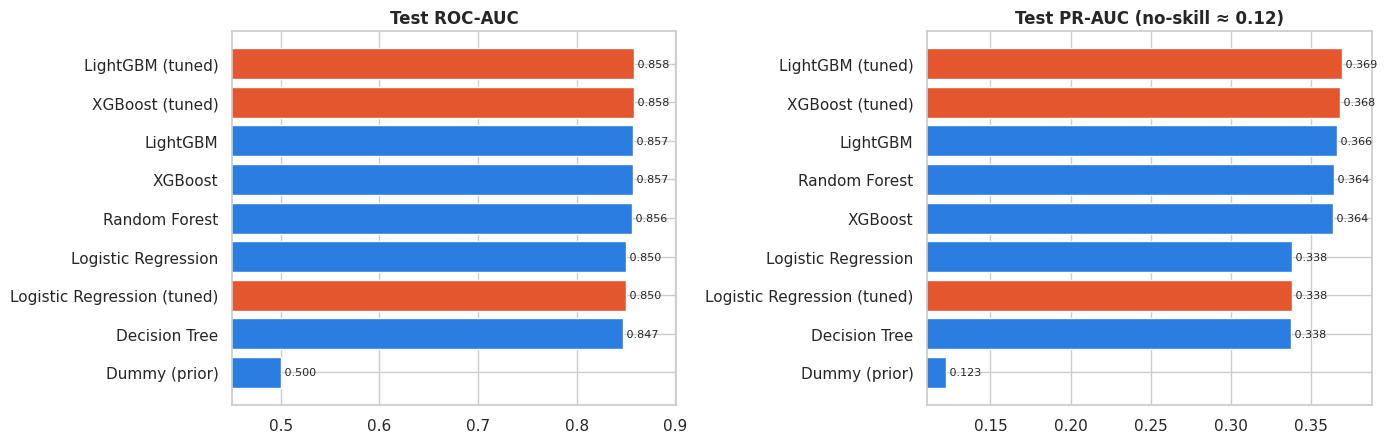

Effect of tuning on test PR-AUC:


,before,after,change
model,,,
Logistic Regression,0.3383,0.3380,-0.0003
LightGBM,0.3665,0.3693,0.0028
XGBoost,0.3637,0.3683,0.0046


In [ ]:
res = pd.DataFrame(rows).set_index("model")
display(res.round(4).sort_values("cv_pr_auc", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for a, col, title in zip(ax, ["test_roc_auc", "test_pr_auc"], ["Test ROC-AUC", "Test PR-AUC (no-skill ≈ 0.12)"]):
    r = res[col].sort_values()
    a.barh(r.index, r.values, color=[PALETTE["accent"] if "tuned" in i else PALETTE["pos"] for i in r.index])
    for i, v in enumerate(r.values): a.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    a.set_title(title); a.set_xlim(r.min() * 0.9 if col == "test_pr_auc" else 0.45, r.max() * 1.05)
plt.tight_layout(); plt.show()

imp = pd.DataFrame({"before": res.loc[["Logistic Regression", "LightGBM", "XGBoost"], "test_pr_auc"]})
imp["after"] = [res.loc[f"{m} (tuned)", "test_pr_auc"] for m in imp.index]
imp["change"] = imp["after"] - imp["before"]
print("Effect of tuning on test PR-AUC:"); display(imp.round(4))

**Did tuning help?** Boosted-tree gains from tuning are usually small on a dataset with only 10 features; the table above quantifies the change honestly. The logistic regression is weaker than the boosted trees (test PR-AUC ≈ 0.34 vs ≈ 0.37) because the age/vehicle-age/region relationships are non-linear and interact (Charts 3, 7, 14). Model choice below is made on **cross-validated** PR-AUC, not on the test set.

## 9. Final model, decision threshold and test-set evaluation

In [ ]:
best_name = res["cv_pr_auc"].idxmax()
final_model = fitted[best_name]
p_test = test_proba[best_name]
print(f"Selected model (highest cross-validated PR-AUC): {best_name}")
display(res.loc[[best_name], ["cv_roc_auc", "cv_pr_auc", "test_roc_auc", "test_pr_auc", "test_recall_top30", "test_lift_top30"]].round(4))

Selected model (highest cross-validated PR-AUC): LightGBM (tuned)


,cv_roc_auc,cv_pr_auc,test_roc_auc,test_pr_auc,test_recall_top30,test_lift_top30
model,,,,,,
LightGBM (tuned),0.8576,0.3702,0.8583,0.3693,0.7928,2.6426


### 9.1 Business assumptions and threshold
A probability is not a decision. The cut-off is chosen from cost/benefit, using **out-of-fold training predictions** (so the test set stays untouched). The two numbers below are **illustrative assumptions – replace them with real figures from the business**:
- cost of contacting one customer = **1** unit
- value of one converted sale = **15** units → break-even probability = 1/15 ≈ 6.7 %

Profit-maximising threshold on out-of-fold predictions: 0.060  (break-even = 0.067)


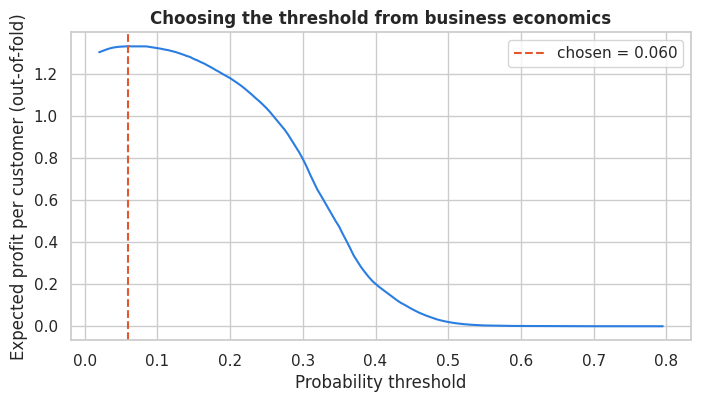

In [ ]:
COST_PER_CONTACT = 1.0
VALUE_PER_CONVERSION = 15.0

oof = cross_val_predict(clone(final_model), X_train, y_train, cv=skf, method="predict_proba")[:, 1]

def profit(y_true, contact):
    y_arr = np.asarray(y_true)
    return y_arr[contact].sum() * VALUE_PER_CONVERSION - contact.sum() * COST_PER_CONTACT

grid = np.round(np.arange(0.02, 0.80, 0.005), 3)
profit_curve = np.array([profit(y_train, oof >= t) / len(y_train) for t in grid])
THRESHOLD = float(grid[profit_curve.argmax()])
print(f"Profit-maximising threshold on out-of-fold predictions: {THRESHOLD:.3f}  (break-even = {COST_PER_CONTACT/VALUE_PER_CONVERSION:.3f})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, profit_curve, color=PALETTE["pos"]); ax.axvline(THRESHOLD, color=PALETTE["accent"], ls="--", label=f"chosen = {THRESHOLD:.3f}")
ax.set_xlabel("Probability threshold"); ax.set_ylabel("Expected profit per customer (out-of-fold)")
ax.set_title("Choosing the threshold from business economics"); ax.legend(); plt.show()

,threshold,accuracy,precision,recall,f1,share_contacted
test @ chosen threshold,0.06,0.6494,0.2563,0.9782,0.4062,0.4678


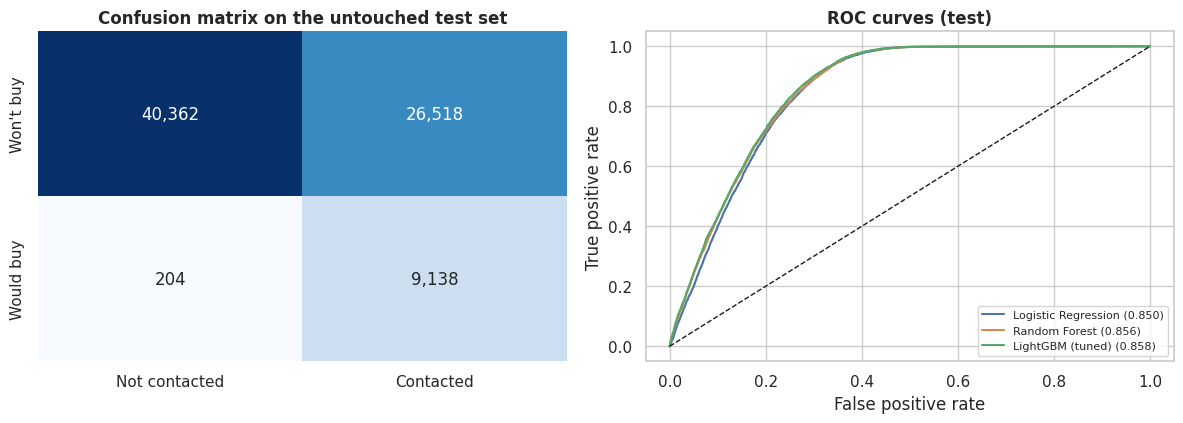

Contacting 46.8% of customers captures 9,138 of 9,342 buyers (recall 97.8%); 26,518 contacts are wasted (precision 25.6%); 204 buyers are missed.


In [ ]:
pred = (p_test >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred)
metrics_at_thr = dict(threshold=THRESHOLD, accuracy=accuracy_score(y_test, pred), precision=precision_score(y_test, pred),
                      recall=recall_score(y_test, pred), f1=f1_score(y_test, pred),
                      share_contacted=pred.mean())
display(pd.Series(metrics_at_thr).round(4).to_frame("test @ chosen threshold").T)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Not contacted", "Contacted"], yticklabels=["Won't buy", "Would buy"])
ax[0].set_title("Confusion matrix on the untouched test set")
for name in ["Logistic Regression", "Random Forest", best_name]:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name]); ax[1].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, test_proba[name]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curves (test)"); ax[1].legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Contacting {pred.mean():.1%} of customers captures {tp:,} of {tp+fn:,} buyers (recall {tp/(tp+fn):.1%}); "
      f"{fp:,} contacts are wasted (precision {tp/(tp+fp):.1%}); {fn:,} buyers are missed.")

**Interpreting the metrics for the business**
- **Recall** = share of real buyers the campaign reaches. Because a sale is worth much more than a call, the profit-optimal threshold deliberately accepts low precision to keep recall high.
- **Precision** = share of contacted people who buy. It will look modest (well under 50 %) – this is expected and economically fine as long as it exceeds the break-even rate (6.7 %).
- **Accuracy** is shown only for completeness; it is misleading with a 12 % positive rate.

### 9.2 Gains, lift and calibration

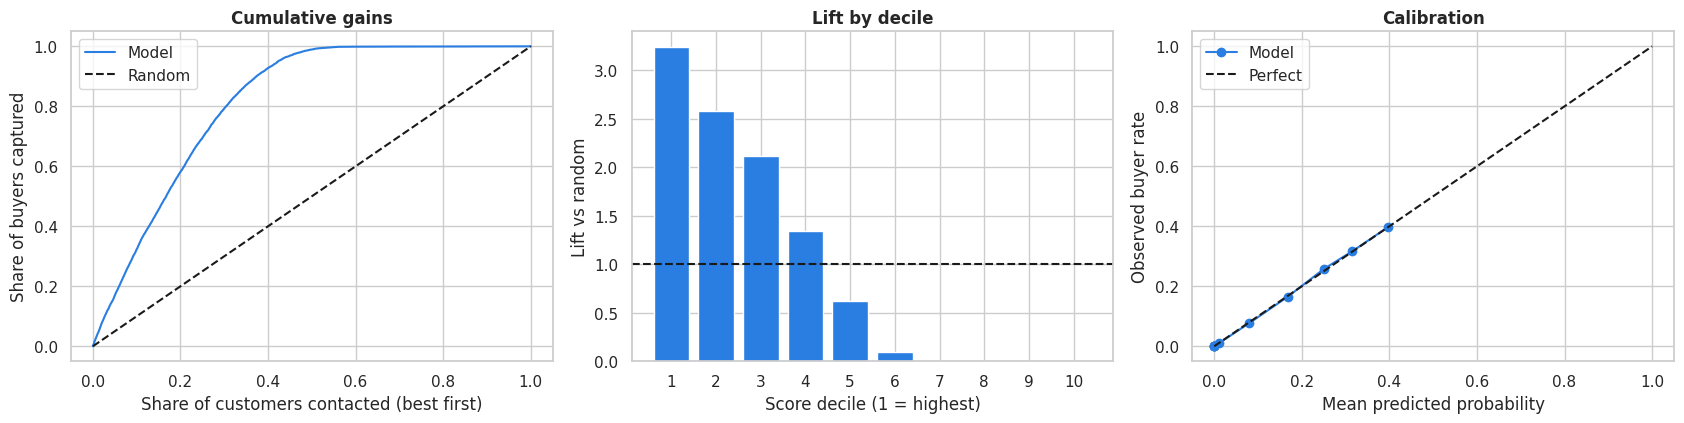

,customers,buyers,response_rate,avg_score,lift,cum_buyers_captured
decile,,,,,,
1,7623,3025,0.397,0.396,3.238,0.324
2,7622,2411,0.316,0.315,2.581,0.582
3,7622,1971,0.259,0.251,2.110,0.793
4,7622,1258,0.165,0.168,1.347,0.928
5,7622,580,0.076,0.079,0.621,0.990
6,7622,86,0.011,0.012,0.092,0.999
7,7622,4,0.001,0.001,0.004,0.999
8,7622,2,0.000,0.000,0.002,0.999
9,7622,3,0.000,0.000,0.003,1.000


Contacting the top 10% captures 32.4% of buyers; top 30% captures 79.3%; top 50% captures 99.0%.


In [ ]:
order = np.argsort(-p_test)
y_sorted = y_test.to_numpy()[order]
cum_gain = np.cumsum(y_sorted) / y_sorted.sum()
frac = np.arange(1, len(y_sorted) + 1) / len(y_sorted)

dec = pd.DataFrame({"y": y_sorted, "p": p_test[order]})
dec["decile"] = pd.qcut(np.arange(len(dec)), 10, labels=range(1, 11))
decile_tbl = dec.groupby("decile", observed=True).agg(customers=("y", "size"), buyers=("y", "sum"),
                                                     response_rate=("y", "mean"), avg_score=("p", "mean"))
decile_tbl["lift"] = decile_tbl["response_rate"] / y_test.mean()
decile_tbl["cum_buyers_captured"] = decile_tbl["buyers"].cumsum() / decile_tbl["buyers"].sum()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].plot(frac, cum_gain, color=PALETTE["pos"], label="Model"); ax[0].plot([0, 1], [0, 1], "k--", label="Random")
ax[0].set_xlabel("Share of customers contacted (best first)"); ax[0].set_ylabel("Share of buyers captured")
ax[0].set_title("Cumulative gains"); ax[0].legend()
ax[1].bar(decile_tbl.index.astype(str), decile_tbl["lift"], color=PALETTE["pos"]); ax[1].axhline(1, color="k", ls="--")
ax[1].set_xlabel("Score decile (1 = highest)"); ax[1].set_ylabel("Lift vs random"); ax[1].set_title("Lift by decile")
prob_true, prob_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
ax[2].plot(prob_pred, prob_true, "o-", color=PALETTE["pos"], label="Model"); ax[2].plot([0, 1], [0, 1], "k--", label="Perfect")
ax[2].set_xlabel("Mean predicted probability"); ax[2].set_ylabel("Observed buyer rate"); ax[2].set_title("Calibration"); ax[2].legend()
plt.tight_layout(); plt.show()
display(decile_tbl.round(3))
g30 = cum_gain[int(len(frac) * 0.30) - 1]; g10 = cum_gain[int(len(frac) * 0.10) - 1]
print(f"Contacting the top 10% captures {g10:.1%} of buyers; top 30% captures {g30:.1%}; top 50% captures {cum_gain[int(len(frac)*0.5)-1]:.1%}.")

**How to read these:** the *gains curve* shows how quickly buyers are found when the best-scored customers are called first (the diagonal is random calling). *Lift by decile* shows the top deciles convert several times better than average and the bottom deciles almost never. The *calibration plot* shows predicted probabilities track observed rates (points near the diagonal), so the score can be read as a genuine purchase probability – which is what makes the cost/benefit threshold meaningful.

### 9.3 What drives the predictions? (permutation importance on raw features)

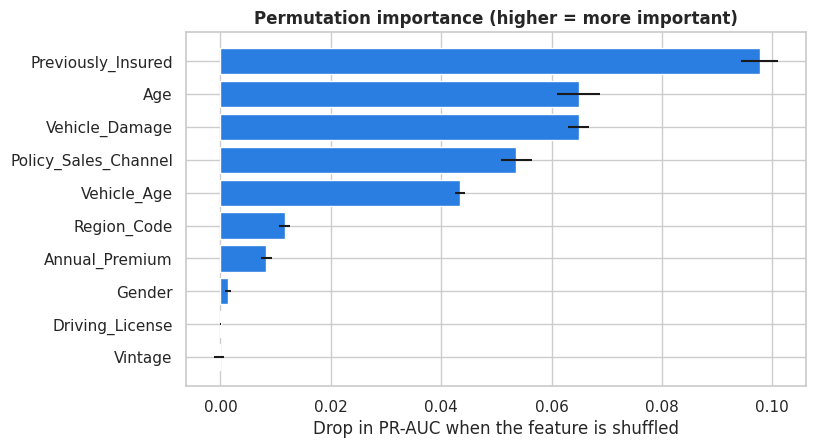

,importance
Previously_Insured,0.0977
Age,0.0649
Vehicle_Damage,0.0649
Policy_Sales_Channel,0.0536
Vehicle_Age,0.0434
Region_Code,0.0116
Annual_Premium,0.0083
Gender,0.0013
Driving_License,0.0000
Vintage,-0.0002


In [ ]:
samp = X_test.sample(30_000, random_state=SEED)
pi = permutation_importance(final_model, samp, y_test.loc[samp.index], scoring="average_precision",
                            n_repeats=3, random_state=SEED, n_jobs=1)
importance = pd.Series(pi.importances_mean, index=samp.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(importance.index, importance.values, xerr=pd.Series(pi.importances_std, index=samp.columns).loc[importance.index],
        color=PALETTE["pos"]); ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title("Permutation importance (higher = more important)"); plt.show()
display(importance.sort_values(ascending=False).round(4).to_frame("importance"))

**Insight:** the model leans on the signals found in the EDA – vehicle damage, prior insurance, age, sales channel, region and vehicle age. `Vintage`, `Annual_Premium` and `Driving_License` contribute very little, which matches Charts 8–10 and confirms the model is not leaning on noise. Permutation importance is computed on the *raw* columns through the whole pipeline, so it is directly interpretable by the business.

## 10. Business impact on the held-out customers

In [ ]:
n = len(y_test); buyers = int(y_test.sum()); contacted = pred.astype(bool)
y_arr = y_test.to_numpy()
impact = pd.DataFrame({
    "Contact everyone":              dict(contacts=n,                     buyers_reached=buyers,                  profit=profit(y_arr, np.ones(n, bool))),
    f"Model @ threshold {THRESHOLD:.3f}": dict(contacts=int(contacted.sum()), buyers_reached=int(y_arr[contacted].sum()), profit=profit(y_arr, contacted)),
    "Random, same volume":           dict(contacts=int(contacted.sum()),  buyers_reached=int(round(contacted.sum() * y_arr.mean())),
                                          profit=contacted.sum() * y_arr.mean() * VALUE_PER_CONVERSION - contacted.sum() * COST_PER_CONTACT),
}).T
impact["profit_per_1000_customers"] = impact["profit"] / n * 1000
display(impact.round(1))
uplift = impact.iloc[1]["profit"] / impact.iloc[0]["profit"] - 1
saved = 1 - impact.iloc[1]["contacts"] / n
print(f"Versus contacting everyone, the model reaches {impact.iloc[1]['buyers_reached']/buyers:.1%} of buyers with {saved:.1%} fewer contacts "
      f"and {uplift:+.1%} profit (under the stated cost/value assumptions).")

,contacts,buyers_reached,profit,profit_per_1000_customers
Contact everyone,76222.0,9342.0,63908.0,838.4
Model @ threshold 0.060,35656.0,9138.0,101414.0,1330.5
"Random, same volume",35656.0,4370.0,29895.6,392.2


Versus contacting everyone, the model reaches 97.8% of buyers with 53.2% fewer contacts and +58.7% profit (under the stated cost/value assumptions).


**Takeaway:** the model is valuable mainly as a **budget-saver and prioritiser** – it drops the large mass of customers who will never buy (previously insured / no past damage / low-yield channels) while keeping most real buyers. Absolute profit numbers depend entirely on the cost and sale-value assumptions, which must be replaced with real figures before any financial claim is made.

## 11. Save the model and metadata for the Streamlit app
The saved object is a single scikit-learn `Pipeline` that accepts **raw columns** (`Gender`, `Vehicle_Age`, `Vehicle_Damage` as text), so the app cannot drift from the notebook's preprocessing. Run the app with `streamlit run app.py`.

In [ ]:
Path("models").mkdir(exist_ok=True)
joblib.dump(final_model, "models/final_pipeline.joblib", compress=3)

region_stats = df.groupby("Region_Code")["Response"].agg(["size", "mean"]).sort_values("size", ascending=False)
channel_stats = df.groupby("Policy_Sales_Channel")["Response"].agg(["size", "mean"]).sort_values("size", ascending=False)
row = res.loc[best_name]
meta = {
    "model_name": best_name,
    "features": FEATURES,
    "threshold": THRESHOLD,
    "cost_per_contact": COST_PER_CONTACT,
    "value_per_conversion": VALUE_PER_CONVERSION,
    "base_rate": float(y.mean()),
    "n_customers": int(len(df)),
    "metrics": {k: float(row[k]) for k in ["cv_roc_auc", "cv_pr_auc", "test_roc_auc", "test_pr_auc", "test_recall_top30", "test_lift_top30"]},
    "metrics_at_threshold": {k: float(v) for k, v in metrics_at_thr.items()},
    "model_comparison": res.round(4).reset_index().to_dict(orient="records"),
    "decile_table": decile_tbl.reset_index().assign(decile=lambda d: d["decile"].astype(int)).round(4).to_dict(orient="records"),
    "feature_importance": {k: float(v) for k, v in importance.sort_values(ascending=False).items()},
    "score_quantiles": [float(v) for v in np.quantile(p_test, np.linspace(0, 1, 101))],
    "ranges": {"Age": [int(df.Age.min()), int(df.Age.max())],
               "Annual_Premium": [float(df.Annual_Premium.min()), float(df.Annual_Premium.max())],
               "Vintage": [int(df.Vintage.min()), int(df.Vintage.max())]},
    "regions": [{"code": float(k), "customers": int(v["size"]), "rate": float(v["mean"])} for k, v in region_stats.iterrows()],
    "channels": [{"code": float(k), "customers": int(v["size"]), "rate": float(v["mean"])} for k, v in channel_stats.iterrows()],
}
Path("models/meta.json").write_text(json.dumps(meta, indent=2))

# round-trip check: the reloaded artefact must reproduce the in-memory predictions exactly
reloaded = joblib.load("models/final_pipeline.joblib")
assert np.allclose(reloaded.predict_proba(X_test.head(500))[:, 1], final_model.predict_proba(X_test.head(500))[:, 1])
print("Saved models/final_pipeline.joblib and models/meta.json – reload check passed.")

Saved models/final_pipeline.joblib and models/meta.json – reload check passed.


## 12. Conclusion

In [ ]:
m = meta["metrics"]; t = metrics_at_thr
Markdown(f"""
**Model.** **{best_name}** was selected on cross-validated PR-AUC ({m['cv_pr_auc']:.3f}) and confirmed once on the untouched test set:
ROC-AUC **{m['test_roc_auc']:.3f}**, PR-AUC **{m['test_pr_auc']:.3f}** (no-skill ≈ {y.mean():.3f}), lift in top 30 % **{m['test_lift_top30']:.2f}×**,
and **{m['test_recall_top30']:.1%} of buyers** found by contacting only the top 30 % of customers (top 50 %: **{cum_gain[int(len(frac)*0.5)-1]:.1%}**, because roughly half the base – insured or undamaged customers – almost never buys).

**Decision rule.** With the stated cost/value assumptions, contacting customers whose score is ≥ {THRESHOLD:.3f} reaches
{t['recall']:.1%} of buyers while contacting {t['share_contacted']:.1%} of the base.

**Key findings.**
1. Prior vehicle insurance and past vehicle damage are the dominant signals: previously insured customers almost never buy (≈ 0.1 %), and not-insured-with-damage customers convert at 25 %.
2. Response is non-linear in age (peak 36–55) and rises with vehicle age; many young customers are simply already insured.
3. Sales channel and region matter a lot: the highest-volume channel (152) converts at 2.9 % versus ~19–20 % for others.
4. Tenure (`Vintage`) and the licence flag carry essentially no information.

**Limitations.**
- Cost per contact and sale value are **assumptions**; the threshold and profit figures change with real numbers.
- The data is a single snapshot with no dates, so it cannot show seasonality or whether the model degrades over time.
- `Region_Code` and `Policy_Sales_Channel` are anonymised, so the *reasons* for regional/channel differences cannot be explained.
- The dataset has no causal information (e.g. whether contact itself changes behaviour); the score ranks likelihood, not persuadability.
- Gender is available as a feature; check fairness/regulatory rules before using it in production.

**Next steps.** Add policy-renewal dates (timing is probably key for young/new-vehicle customers), calibrate and monitor the score in production,
run an A/B test of model-ranked versus current targeting, and test target encoding for region/channel.
""")


**Model.** **LightGBM (tuned)** was selected on cross-validated PR-AUC (0.370) and confirmed once on the untouched test set:
ROC-AUC **0.858**, PR-AUC **0.369** (no-skill ≈ 0.123), lift in top 30 % **2.64×**,
and **79.3% of buyers** found by contacting only the top 30 % of customers (top 50 %: **99.0%**, because roughly half the base – insured or undamaged customers – almost never buys).

**Decision rule.** With the stated cost/value assumptions, contacting customers whose score is ≥ 0.060 reaches
97.8% of buyers while contacting 46.8% of the base.

**Key findings.**
1. Prior vehicle insurance and past vehicle damage are the dominant signals: previously insured customers almost never buy (≈ 0.1 %), and not-insured-with-damage customers convert at 25 %.
2. Response is non-linear in age (peak 36–55) and rises with vehicle age; many young customers are simply already insured.
3. Sales channel and region matter a lot: the highest-volume channel (152) converts at 2.9 % versus ~19–20 % for others.
4. Tenure (`Vintage`) and the licence flag carry essentially no information.

**Limitations.**
- Cost per contact and sale value are **assumptions**; the threshold and profit figures change with real numbers.
- The data is a single snapshot with no dates, so it cannot show seasonality or whether the model degrades over time.
- `Region_Code` and `Policy_Sales_Channel` are anonymised, so the *reasons* for regional/channel differences cannot be explained.
- The dataset has no causal information (e.g. whether contact itself changes behaviour); the score ranks likelihood, not persuadability.
- Gender is available as a feature; check fairness/regulatory rules before using it in production.

**Next steps.** Add policy-renewal dates (timing is probably key for young/new-vehicle customers), calibrate and monitor the score in production,
run an A/B test of model-ranked versus current targeting, and test target encoding for region/channel.
